### Metahuristics Assigment


#### Part One: Hill climbing algorithm implementation

In [2]:
import numpy as np
import time 
import matplotlib.pyplot as plt
import mplcursors
import seaborn as sns
import mplcursors
import pandas as pd
import ipympl
import sys
sys.path.append("../helper")
from workload_data_loader import load_workload_instance as ld
from itertools import combinations
from scipy.stats import friedmanchisquare
from scipy.optimize import milp, LinearConstraint, Bounds
print(ipympl.__version__)

0.10.0


Helper functions for one instance
- fitness(x):evaluation of total utility
- is_feasible(x):evaluation of constraints passed over or not

In [3]:
def fitness(x:np.ndarray,p:np.ndarray):
   return p @ x

def is_feasible(x:np.ndarray,r:np.ndarray,b:np.ndarray):
    return np.all(r @ x <= b)

Helper: Generation of initial state using seed so its reproducible

In [4]:
# rng = np.random.default_rng(44)
def generate_initial_state(seed,size:int,demands,capacities):
    # Will repeat until initial feasible state is acquired although the deterministic first value for seed 42 is feasible anywhay
    while True:
        x = seed.integers(0,2,size=size)
        if(is_feasible(x,demands,capacities)): 
            # print(f"fitness :{fitness(x,utilities)}")
            return x

Neighbourhood / Manipulation Functions 

In [5]:
# Neighbourhood manipulation function: 
# single bit manipulation
def generate_neighbour_single_bit(x:np.ndarray):
    neighbours = []
    for i in range(len(x)):
        neighbour = x.copy()
        neighbour[i] = 1-x[i]
        neighbours.append(neighbour)
    return np.array(neighbours)

# multi bit manipulation
# The logic is using xor bit manipulation with a mask containing 1 where you want to change values
# and 0 where you dont
# the combination function allows us to create all the combinations possible for that exact length and bit manipulation number
# 28Ck(bit manipulation number)

def generate_neighbours_multi_bit(x:np.ndarray,k:int):
    n = len(x)
    # Creating all the combinations for the length and bit manipulation number
    positions = list(combinations(range(n),k))
    # Create a mask for it 
    masks = np.zeros((len(positions),n),dtype=int)
    for i,pos in enumerate(positions):
        masks[i, list(pos)] = 1
        
    return np.bitwise_xor(x,masks)

# This pairing will create all the possible pairings for the selected 
# generator function which is also recursive which will make all the pairing we need for the swaps in 
# it takes in all the pisitions selected from the combination the tuple
# Then produces each distict pairing for it at every yield
# ex (0,1,2,3) positions chosen
def pairings(items):
    # items (0,1,2,3), (2,3)
    if not items: # false,false,true
        yield () # This is the base boolean expression for the recursion basically you will see it returns an empty tuple which joins at the end
        return 
    first = items[0] # 0,2
    for i in range(1,len(items)): #1->4 , #1,2
        second = items[i] #1,3
        remaining = items[1:i] + items[i+1:] # () + (3,4) = (3,4) , () + () = () 
        for rest in pairings(remaining): # Recursive call rest =()
            yield((first,second),) + rest # ((2,3),) + () = (2,3) , ((1,2),) + (2,3) = ((1,2),(2,3)) This is yielded in the for loop in neigbourhood function  

    
    

def generate_neighbours_multi_swap(x:np.ndarray,k:int):
    # We will only go uptil k=2 becuase k=3 by using this formula 28!/(n-2(2))!2^k*k! = 5651100 variations considered
    # which if repeated say 48 times means that it is evaluating same as brute force with maybe even less accuracy
    
    n = len(x)
    neighbours = []
    # 2 multipled because first part is nC2k why? for say one swap you choose two bits out of whole collection of bits
    # so say for two-swap you would choose 4 so it becomes nC2k and this gives us all the combination of selected bits
    # These bits will be seperated into pairs of two which will be use to commence all the swaps
    for selected in combinations(range(n),2*k):
        for pairs in pairings(selected): 
            #pairs 1((0,1),(2,3)), pairs2 ((0,2),(1,3)), pairs3 ((0,3),(1,2))
            # Here basically now just use the position of the swaps to implement the swaps
            neighbour = x.copy()
            for i,j in pairs: #(0,1) , (2,3)
                # Thus neighbour i and j switch the bits
                neighbour[i],neighbour[j] = neighbour[j],neighbour[i]
            neighbours.append(neighbour)
    return np.unique(np.array(neighbours),axis=0)


Constraint Handling Functions

In [6]:
# These will be modularly added same as muatation 

# This will just filter out the values generated in the neighbourhood solution to only contain feasible values
def constraint_handling_rejection(neighbours,utilities,demands,capacities): # Utilities here cause the other constraint handler needs it and function call is not abstracterd
    return np.asarray([neighbour for neighbour in neighbours if is_feasible(neighbour,demands,capacities)])
    

# This will work like this it will calculate the ratios between profits/demands 
# Then remove that exist in the state with the lowest ratio for profit/demand
# Since there are two profit/demands. The way it does is this is check which one is being exceeded
# And then removes the lowest ratio bit for that 
# IF both are over than another ratio caluclated of which one is actually more exceeded_capacity1/demands or exceeded_capacity2/demands
def constraint_handling_greedy_repair(neighbours,utilities,demands,capacities):
    repaired_neighbours = []
    for neighbour in neighbours:
        repaired = neighbour.copy()
        # Infinite loop of removing the bits until feasible
        while not is_feasible(repaired,demands,capacities):
            # Gives out the array which has two values one for the first constraint and one for the next
            loads = demands @ repaired
            # Basically how much is exceeded from capacity
            violations = loads - capacities
            # Tells us  which constraints passed over
            # violated_constraints = violations > 0 # this gives us True,True or True,False or False,True
            
            # Now we need to calculate the relative violations 
            # This combines the above step so if the violation occurs its ratio is calculated if not 0 is placed there
            relative_violations = np.where(violations>0,violations/capacities,0)
            target = np.argmax(relative_violations) # Gives us the index of the higgest violation
            
            # Gives us the indices of the selected points in the current state
            selected_states_indices = np.flatnonzero(repaired)
            # any zero demands item is removed
            candidates = selected_states_indices[demands[target,selected_states_indices] > 0]
            
            # now the ratios for this utility/demand for each item
            ratios = utilities[candidates] / demands[target,candidates]
            # now get the index of the worst item by getting the worst ratio 
            worst_item_index =  candidates[np.argmin(ratios)]
            repaired[worst_item_index] = 0
        repaired_neighbours.append(repaired)
    return repaired_neighbours
            
            

Neigbourhood selction function

In [7]:
# Choosing a better neighbour
def best_neighbour(x:np.ndarray,p:np.ndarray,r:np.ndarray,b,m:callable,constraint_handler,*args):
    neighbours = constraint_handler(m(x,*args),p,r,b)
    best_state = None
    best_fitness = fitness(x,p) 
    evaluations = 0
    for neighbour in neighbours:
        # if is_feasible(neighbour,r,b): This is now modular
            neighbour_fitness = fitness(neighbour,p)
            evaluations += 1
            if neighbour_fitness > best_fitness:
                best_state = neighbour
                best_fitness = neighbour_fitness
                # print(best_fitness)
    return best_state, best_fitness, evaluations

Hill climbing algorithm

In [8]:
def hill_climbing(state,utilities,demands,capacities,mutation,constraint_handler,*args):
    # This will be for the evaluation of runtime of each function
    start_time = time.perf_counter()
    current = state.copy()
    
    evaluations = 1
    # Now for the convergance curve we need fitness per step
    current_fitness = fitness(current,utilities)
    convergence_curve = [current_fitness]
    # We will record number of evaluations per step so we can plot a curve against it
    convergence_evaluation = [evaluations]
    # Iterations will be amount of steps each hill climbing takes
    iterations = 0
    # The number of neighbours explored since at one step different methadologies compare different number of neighbours
    # one for the initial state
    while True:
        # So we get the number from the best neighbour
        best_state, best_fitness, num_evaluations = best_neighbour(current,utilities,demands,capacities,mutation,constraint_handler,*args)
        evaluations  += num_evaluations
        if best_state is None:
            # The final change fitness stays same but evaluations changes
            convergence_curve.append(current_fitness)
            convergence_evaluation.append(evaluations)
            break
        
        current = best_state
        current_fitness = best_fitness
        
        iterations += 1
        convergence_curve.append(current_fitness)
        convergence_evaluation.append(evaluations)
    
    
    end_time = time.perf_counter()
    runtime = end_time - start_time
    # I forgot you could returns dicts kinda looks like js    
    return {
        "solution" : current,
        "fitness" : current_fitness,
        "iterations" : iterations,
        "evaluations" : evaluations,
        "convergence_points" : convergence_curve ,
        "convergence_evaluations" : convergence_evaluation,
        "runtime" : runtime
    }




  

Dict to keep all the strategies named
mutation/neighbourhood function call, arguments

In [9]:
neighbourhoods = {
    "1-bit" : (generate_neighbour_single_bit,()),
    "2-bit" : (generate_neighbours_multi_bit,(2,)),
    "3-bit" : (generate_neighbours_multi_bit,(3,)),
    "4-bit" : (generate_neighbours_multi_bit,(4,)),
    "1-swap" : (generate_neighbours_multi_swap,(1,)),
    "2-swap" : (generate_neighbours_multi_swap,(2,)),
}

constraint_handlers = {
    "rejection" : constraint_handling_rejection,
    "greedy_repair" : constraint_handling_greedy_repair
}

Run function for running all the different variations and getting their respective results from the hill climbing 

In [10]:
def run_exp(
    neighbourhoods: dict,
    num_runs,
    utilities,
    demands,
    capacities,
    size = 28,
    seed = 44,
    constraint_handlers = None
):
    rng = np.random.default_rng(seed)
    #  The results will be organized by their 
    # names each key in dict, 
    # values will be the appended runs depending on number of run so an array of dict containg result for each run
    results = {}
    
    # comprehension to generate initial states depending on no of runs
    initital_states = [generate_initial_state(rng,size,demands,capacities) for _ in range(num_runs)]
    
    # Here if we dont add constraint_handlers it will default to rejection
    if constraint_handlers is None: 
        constraint_handlers = {"rejection" : constraint_handling_rejection}
    
    # now first loop is going to be using the above dict for definitions deconstruciton
    for neighbourhood_name,(methods,args) in neighbourhoods.items():
        # Now we loop through the constraint handlers too so its neighbourhood1constraint1,neighbourhood1constraint2
        for constraint_name,constraint_funct in constraint_handlers.items():
            runs = []
            # The second loop will be using the initial states we defined 
            for initial_state in initital_states:
                result = hill_climbing(initial_state,utilities,demands,capacities,methods,constraint_funct,*args)
                runs.append(result)
            # We will name it using both now
            results[f"{neighbourhood_name} | {constraint_name}"] = runs
    return results

    

Baseline method for getting exact value for comparison in statistics

In [11]:
def solve_mkp_scipy(utility, demands, capacities, time_limit=600):
    c = -np.array(utility)                    
    cons = LinearConstraint(np.array(demands), -np.inf, np.array(capacities))
    res = milp(c, constraints=cons,
               integrality=np.ones(len(utility)),
               bounds=Bounds(0, 1),
               options={"time_limit": time_limit})
    return -res.fun, res.x.round().astype(int), res.status 

Evaluation function here all the results collected in the dict the raw variables and calculated variables generated for evaluation

In [12]:
def analyse_results(results,optimal_fitness):
    # The analysis is done on two basis 
    # Solution quality : mean fitness,best fitness, standard deviations of fitness 
    # Solution efficiency: iterations,evaluatoins, runtime 
    # Both analytics togethar are also shown represented using convergance graphs later
    analysis = {}
    
    # We will create numpy arrays from initial results seperating each raw variable
    # using comprehension
    for name,runs in results.items():
        # Fitness values
        fitness_values = np.array([run["fitness"] for run in runs])
        # Iterations
        iteration_values = np.array([run["iterations"] for run in runs])
        # Evaluations
        evaluation_values = np.array([run["evaluations"] for run in runs])
        # RunTimes 
        runtime_values = np.array([run["runtime"] for run in runs])
        
        # Convergance_Iterations
        # First of all see the sizes of convergance values for arrats are gonna be different as
        # differnt position starting means they end at different points so length not same so pad the smaller oness 
        # so they are same size so we can calculate mean convergance for same number of iteration how by repeating the same value over the other iterations
        convergence_curves = [run["convergence_points"] for run in runs]
        biggest_length_curve = max(len(curve) for curve in convergence_curves)
        
        # Padding the last value from the curve at the end of the curves which are short
        padded_curves = np.array([np.pad(curve,(0,biggest_length_curve-len(curve)),constant_values=curve[-1]) for curve in convergence_curves])
         
        
        # Convergance_Evaluations
        # This is going to be complex say we have reject constraint handling and 4-bit strategy
        # The number of evaluations may be different because of reject and number of iterations too because of different starting points
        # ex: convergence_points1[5,8,9] ev1[10,50,100] convergence_points2[6,9] ev2[20,100]
        # What we want at the end for comparison for means and plotting would be same sized arrays to account for iterations
        # ev[10,20,50,100]
        # convergence_points1[5,5,8,9]
        # convergence_points2[Nan,6,6,9]
        # Now its easy to calculate the means for the algorithms altogethar and plot the runs
        
        # joined ev
        enumeration_values_combined = np.unique(np.concatenate([run["convergence_evaluations"] for run in runs]))
        alligned_curves_evaluation = []
        for run in runs:
            xs = np.asarray(run["convergence_evaluations"])
            ys = np.asarray(run["convergence_points"])
            # This is pretty cool this will check the evaluation points
            # ex ev1[10,50,100] ev[10,20,50,100] and give indices for where it would fit we 
            indices = np.searchsorted(xs,enumeration_values_combined,side="right") - 1
            # Here there still will be -1 values which we cant use as index so we replace them with Nan using mask
            valid = indices >= 0
            
            # Initialize it fully with nan
            alligned = np.full(len(enumeration_values_combined),np.nan)
            
            alligned[valid] = ys[indices[valid]]
            alligned_curves_evaluation.append(alligned)
        
        analysis[name] = {
            "mean_fitness" : np.mean(fitness_values),
            "best_fitness" : np.max(fitness_values),
            "worst_fitness" : np.min(fitness_values),
            "std_fitness" : np.std(fitness_values),
            
            # This is convergence per evaluation which is better representation of perfomance as compuation is kept same here
            # unlike mean_convergence using iteration which will use 10time or 20 times computaiton but both will be one iteratioon"
            "mean_convergence_evaluations" : np.mean(alligned_curves_evaluation,axis=0),
            "std_convergence_evaluations" : np.std(alligned_curves_evaluation,axis=0),
            "enumeration_count__convergence" : enumeration_values_combined,
            
            # This is added recently to see another statistical refrence
            "diff_mean_fitness" : optimal_fitness - np.mean(fitness_values),
            "diff_best_fitness" : optimal_fitness - np.max(fitness_values),
            "diff_worst_fitness" : optimal_fitness - np.min(fitness_values),
            
            "mean_iterations" : np.mean(iteration_values),
            "mean_evaluations" : np.mean(evaluation_values),
            "mean_runtime" : np.mean(runtime_values),
            
            "mean_convergence" : np.mean(padded_curves,axis=0),
            "std_convergence" : np.std(padded_curves,axis=0)
        }
    return analysis
        

Function for plotting of curves

In [13]:
# This will take all the mean convergances at y and at x make a no of iterations from the length of the mean convergances

# Fix: The convergance curve will be changed you can see it in the commits it will now be evaluated based of each evaluation considered 
 

# Making this dynamic to support iterations and evaluations
def plot_convergance(analysis:dict,x_axis = "iterations"):
    if x_axis == "iterations":
        x_key = None
        mean_key = "mean_convergence"
        std_key = "std_convergence"
        x_label = "Iterations"
        title = "Iterations"
    elif x_axis == "evaluations":
        x_key = "enumeration_count__convergence"
        mean_key = "mean_convergence_evaluations"
        std_key = "std_convergence_evaluations"
        x_label = "Evaluations"
        title = "Evaluations"        
    sns.set_theme(style="whitegrid")
    fig,ax = plt.subplots()
    
    lines = []
    line_data = {}
    
    for name,data in analysis.items():
         
        mean = np.asarray(data[mean_key])
        std = np.asarray(data[std_key])
        iterations = np.arange(len(mean)) if x_key is None else np.asarray(data[x_key])  
        
        # Each curve gets the name of the mutation attached to it
        line, = ax.plot(iterations,mean, label=name, linewidth = 2)        
        
        # This shaded area will tell us how spread about the values are from the mean the smaller the better
        # as deviation less results more consistent
        # The cosistency of values is covering eachother so i am going to add hover
        band = ax.fill_between(
            iterations,
            mean-std,
            mean+std,
            alpha=0.15,
            color = line.get_color(),
            visible= False
        )
        # Storing the line
        lines.append(line)
        # Storing the data
        line_data[line] = {
            "name" : name,
            "mean" : mean,
            "std" : std,
            "band" : band
        }
        
        
    cursor = mplcursors.cursor(lines,hover=True)
    fig._cursor = cursor
    
    @cursor.connect("add")
    def on_hover(sel):
        info = line_data[sel.artist]
        index = int(round(sel.index))
        index = max(0, min(index, len(info["mean"]) - 1))
        mean = info["mean"][index]
        std = info["std"][index]
        
        # This will make the standard deviation +-1 visible
        info["band"].set_visible(True)
        fig.canvas.draw_idle()
        
        sel.annotation.set_text(
            f"{info['name']}\n"
            f"Iteration: {index}\n"
            f"Mean fitness: {mean:.4f}\n"
            f"Std deviation: {std:.4f}\n"
            f"Range: {mean-std:.4f} - {mean+std:.4f}"
        )
    
    @cursor.connect("remove")
    def on_leave(sel):
        # Hides the band when the mouse leaves the line
        line_data[sel.artist]["band"].set_visible(False)
        fig.canvas.draw_idle()
        
    ax.set_xlabel(x_label)
    ax.set_ylabel("Mean best fitness")
    ax.set_title(f"Mean Convergence Curves {title}")
    ax.legend()
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    plt.show()
        
        

Box plot for showing median and outliers which show points that may get stuck in local optima and visual representation of the deviation

In [14]:
def plor_box_plot(resulsts:dict):
    data = []
    for name,runs in resulsts.items():
        for run in runs:
            data.append({
                "strategy" : name,
                "fitness" : run["fitness"]
            })
            
    # Works cleanly with seaborn
    df = pd.DataFrame(data)
    df.head()
    fig, ax = plt.subplots(figsize=(14, 7))

    sns.boxplot(
        data=df,
        x="strategy",
        y="fitness",
        # hue="Strategy",
        palette="Set2",
        legend=False,
        showmeans=True,
        ax=ax
    )

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=90,
        ha="center"
    )
    ax.set_title("Final Fitness Distribution Across Strategies")
    ax.set_xlabel("Optimisation Strategy")
    ax.set_ylabel("Final Fitness")
    ax.grid(axis="y", alpha=0.25)
    # Giving rotated labels more space
    fig.subplots_adjust(bottom=0.4)
    plt.show()

Friedman Test for evaluating ranking of each strategy also if they are different

In [15]:
def friedman_test(results):
    # Destructuring
    fitness_results = {configuration: [run["fitness"] for run in runs] for configuration, runs in results.items()}
    evaluation_results = {configuration: [run["evaluations"] for run in runs] for configuration, runs in results.items()}
    runtime_results = {configuration: [run["runtime"] for run in runs] for configuration, runs in results.items()}
    fitness_test = friedmanchisquare(*fitness_results.values())
    evaluation_test = friedmanchisquare(*evaluation_results.values())
    runtime_test = friedmanchisquare(*runtime_results.values())
    
    print("Fitness p-value:", fitness_test.pvalue,)
    print("Evaluations p-value:", evaluation_test.pvalue)
    print("Runtime p-value:", runtime_test.pvalue)
    print("Fitness Statistics",fitness_test.statistic)
    print("Evaluation Statistics",evaluation_test.statistic)
    print("Runtime Statistics",runtime_test.statistic)
    
    

In [16]:
n, m, utilities, demands, capacities = ld(r"..\data\multi_resource_n28_m2.txt")
print("=== Dataset Ingestion Summary ===")
print(f"Number of candidate models (n) : {n}")
print(f"Number of resource bounds (m)  : {m}")
print(f"Utility scores shape (p_j)     : {utilities.shape}")
print(f"Resource demands shape (r_ij)  : {demands.shape}")
print(f"Capacity limits (b_i)          : {capacities}")


=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m)  : 2
Utility scores shape (p_j)     : (28,)
Resource demands shape (r_ij)  : (2, 28)
Capacity limits (b_i)          : [500. 500.]


In [17]:
# The actual optimal solution is found using the scipy milp solver which is a branch and bound method for mixed integer linear programming problems.
best_optimal_fitness, best_optimal_solution, status = solve_mkp_scipy(utilities, demands, capacities)
print(f"Optimal fitness: {best_optimal_fitness}")
print(f"Optimal solution: {best_optimal_solution}")
print(f"Solver status: {status} = (0 = optimal, 1 = feasible, 2 = infeasible, 3 = unbounded, 4 = iteration limit reached, 5 = time limit reached)")

Optimal fitness: 130883.0
Optimal solution: [0 0 1 0 1 0 1 1 0 1 1 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0]
Solver status: 0 = (0 = optimal, 1 = feasible, 2 = infeasible, 3 = unbounded, 4 = iteration limit reached, 5 = time limit reached)


In [18]:
results = run_exp(neighbourhoods,10,utilities,demands,capacities,constraint_handlers=constraint_handlers)



In [19]:
analysis = analyse_results(results,best_optimal_fitness)
print("=== Analysis Summary ===")
for name,metrics in analysis.items():
    print(f"{'=' * 50}")
    print(f"Neighbourhood: {name}")
    print(f"{'=' * 50}")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value}")

=== Analysis Summary ===
Neighbourhood: 1-bit | rejection
  mean_fitness: 100254.3
  best_fitness: 115010.0
  worst_fitness: 77482.0
  std_fitness: 11701.458388166837
  mean_convergence_evaluations: [ 58378.   58875.5  63143.5  67398.3  68586.3  74101.8  79617.3  79665.2
  81308.2  81805.7  84056.4  85244.4  86419.2  88854.7  91290.2  93540.9
  94418.4  94613.4  95110.9  96847.4  96896.4  98084.4  98279.4  98701.9
  98760.8  98844.8  98844.8  99039.8  99494.8  99494.8  99494.8  99505.8
  99805.3  99816.3  99872.3  99872.3  99872.3 100067.3 100067.3 100116.3
 100172.3 100172.3 100221.3 100254.3 100254.3]
  std_convergence_evaluations: [19544.39949448 19944.7451187  18580.83888983 15977.68316152
 17136.66170554 16086.45779406 12990.46526534 12981.6172937
 11926.26183513 12360.11017791  9784.07415344  9688.60798257
 10847.30352484 12906.82477645 14991.53458989 13813.23019029
 13332.89409843 13348.87163921 13252.86977564 12849.87723054
 12916.67637746 13331.13957019 13461.65150492 12692.27

In [20]:
%matplotlib widget
# This will make the return from server side of the notbooks interactive not a standard png 

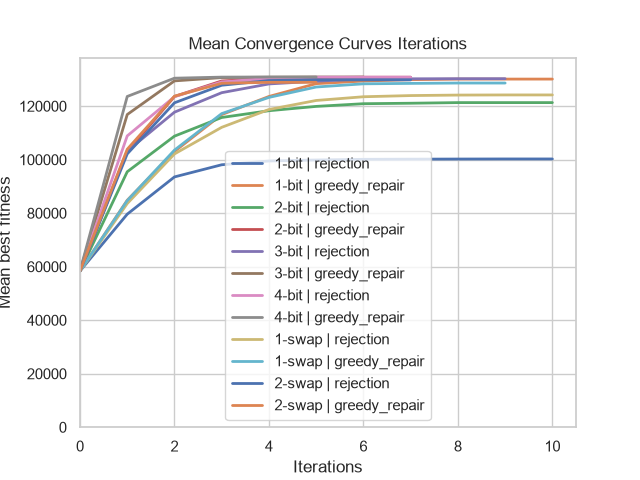

In [21]:
# The graphs
plot_convergance(analysis)

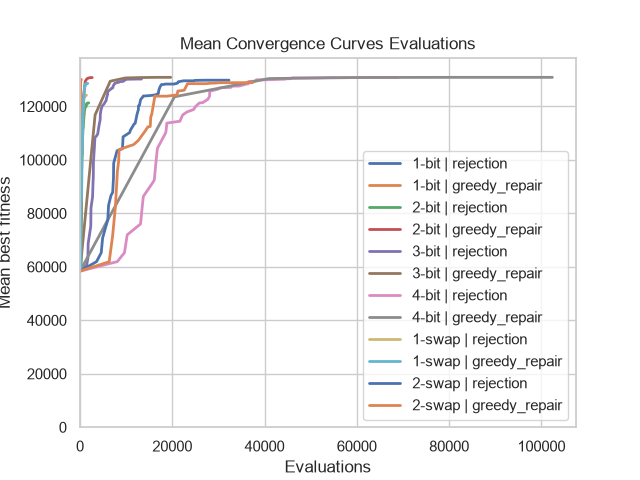

In [22]:
# plotting the convergance curve
plot_convergance(analysis,"evaluations")

C:\Users\Admin\AppData\Local\Temp\ipykernel_10748\78374113.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Admin\AppData\Local\Temp\ipykernel_10748\78374113.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(


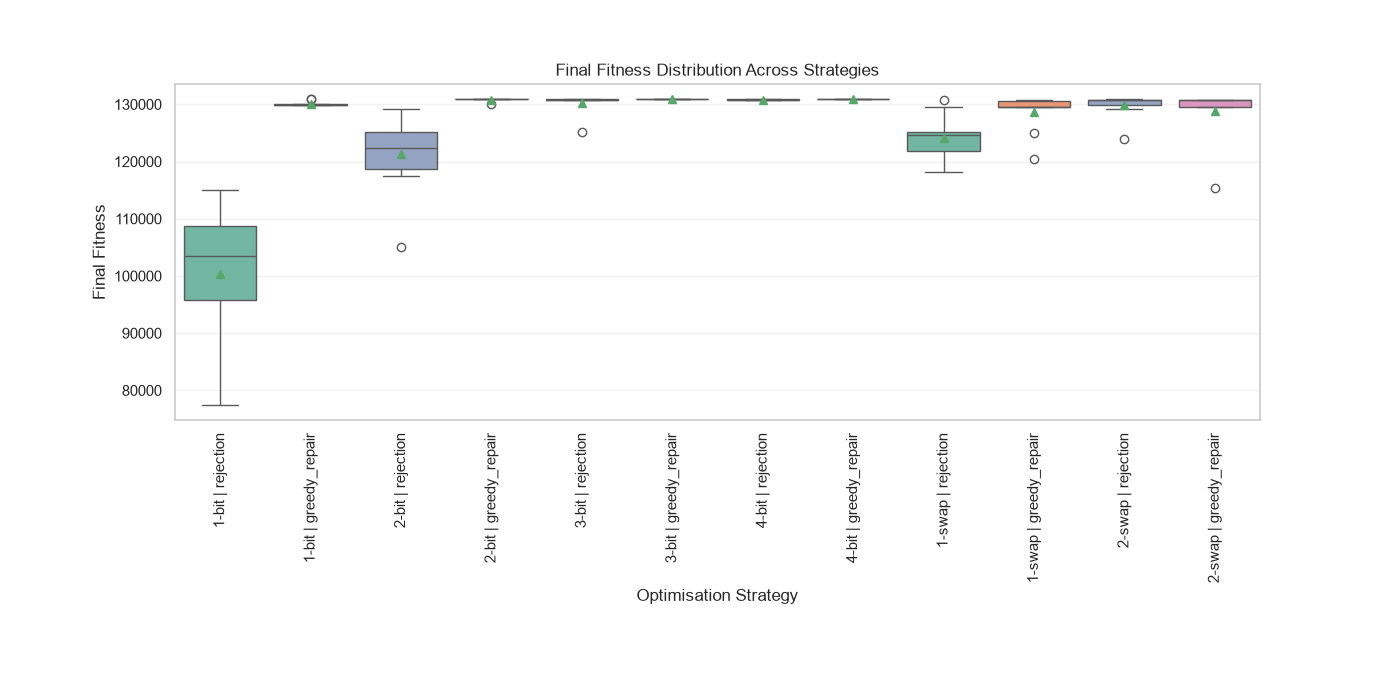

In [23]:
plor_box_plot(results)
# See some of the swap strategies do get stuck in local optima even for really consistent resulst one or to outliers

In [24]:
friedman_test(results)
# this is stupid i though it would show ranks too i can even tell that in each measurement one overpowers the other

Fitness p-value: 1.3097286061674665e-14
Evaluations p-value: 2.9010524144874024e-18
Runtime p-value: 6.8680870551305195e-18
Fitness Statistics 90.53465717497195
Evaluation Statistics 109.0
Runtime Statistics 107.12307692307695


#### Final Strategy + Outcomes: 
The results from this show that greedy repair substantioly optimizes the bit flip flaps compared to rejection constraints. Also increasing the the bit-flip size generally leads to higher solution quality, although it comes with cost of increased runtimes and objective evaluations nCm. (First Choice)The 3-bit greedy pair like its peer 4-bit greedy achieved highest mean fitness of 130,833 with standard deviation of 0 meaning at the end of its iterations it reached a consistent and correct value for this 28 bit problem over 10 different runs.(Second Choice) The 2-bit greedy achieved a mean fitness of 130,796 with standard deviation of 261, while requiring less compuatition this less compuation will scale between the difference of nC3 and nC2 also greedy might change these amount of evaluations.So if computaion efficiency becomes more of a priority then 2-bit will reign more supreme but for smaller problems with less computation charge 3-bit greedy is the first choice

#### Algorithms Insight from results

Muatation strategies and constraints are responsible for results in hill climbing algorithms so lets explore them. Mutation strategies decide which steps you can take in an algorithm and what results you can achieve. If the whole problem is a landscape with a hills than mutation is the pattern you move around it to reach higher and at each eachstep you get distint routes you can follow. So how does this translate to our mutations? Lets first look at the bit flip bit flips as discussed can change the number of items that are selected at a certain time 1 bit can make you remove one or add one item 2 can allow more combinations and 3 so on the changes therefore are huge at each step. A swap essentially removes an item but also has to then add an item it cant have variations like adding two items and removing none etc for each item removed one is added[The 1,1 0,0 swaps not counted even in our algorithm] this is a bottlekneck in a sense as maybe better solutions would require adding whole new items or removing whole new items but swap cant do that it preserves the number.No why does greedy help the bit flip flap well it allows for more available steps by repairing steps that couldnt be taken whereas in this problem that doesnt work with swap because swap and greedy can cause conflicts too by removing items that might make up good solutions swap already is bottlenecked by the non changing of items selected the greedy removes even more items. Now another important point greedy sclaes very quick and 2-swap has a more neighbours to choose from at each step same as 4 bit but 4 bit perfomes better why? Its because its neighbourhood quality is better because it can vary its neighbours 4 different way add 4 items remove 4 and all the combinations in between but swap is limited to moving 4 bits between eachother still preserving the number of items. 